# 02 - Calendar validation, classical ML and ablations

Qidian (Martin) Xing. Independent extension with disclosed Codex assistance. The historical period was previously inspected. Source data and row-level predictions are not redistributed.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "src"))
from distress_ml.common import ROOT, PUBLIC, ART
pd.set_option("display.max_columns", 12)
print("Independent extension: saved real-data evidence; no training is triggered.")


Independent extension: saved real-data evidence; no training is triggered.


## Question
Where do improvements come from?

## Logic
Separate fixed-recipe information/sampling ablations from optimized pipelines. Select by seven-year development AP; keep calibration and decision roles separate. Original team scores are archival and are not controlled baselines.

In [2]:
from distress_ml.splits import DEVELOPMENT
display(pd.DataFrame(DEVELOPMENT, columns=["fold", "fit_end", "score_start", "score_end"]))
development = pd.read_csv(PUBLIC / "development_summary.csv")
display(development[["family", "feature_set", "stage", "macro_year_AP", "worst_year_AP", "mean_fit_seconds"]].head(14))

,fold,fit_end,score_start,score_end
0,D1,2005,2006,2007
1,D2,2007,2008,2009
2,D3,2009,2010,2011
3,D4,2011,2012,2012


,family,feature_set,stage,macro_year_AP,worst_year_AP,mean_fit_seconds
0,random_forest,S1,bounded_search,0.338011,0.224265,20.517367
1,random_forest,S1,core_recipe,0.290071,0.211883,11.827756
2,residual_mlp,S1,controlled_ablation,0.273532,0.176874,25.324360
3,random_forest,S0,core_recipe,0.266469,0.190871,8.798524
4,catboost,S1,core_recipe,0.246223,0.182655,6.848272
5,xgboost,S2,feature_ablation,0.241976,0.172377,6.421535
6,residual_mlp,S1,controlled_ablation,0.240091,0.162592,28.423375
7,xgboost,S1,controlled_ablation,0.236925,0.173416,4.893295
8,xgboost,S1,controlled_ablation,0.235396,0.168262,5.350777
9,xgboost,S1,controlled_ablation,0.235111,0.170237,4.848976


family,residual_mlp,xgboost
recipe,,
No clipping,0.208027,0.233033
ROS,0.273532,0.235396
S0 raw,0.197154,0.224626
S1 base,0.205995,0.232169
S2 dynamics,0.191243,0.241976
SMOTE,0.240091,0.194620
Weight alpha 0.5,0.189172,0.236925
Weight alpha 1,0.190372,0.235111
elastic_net,0.188209,0.229349


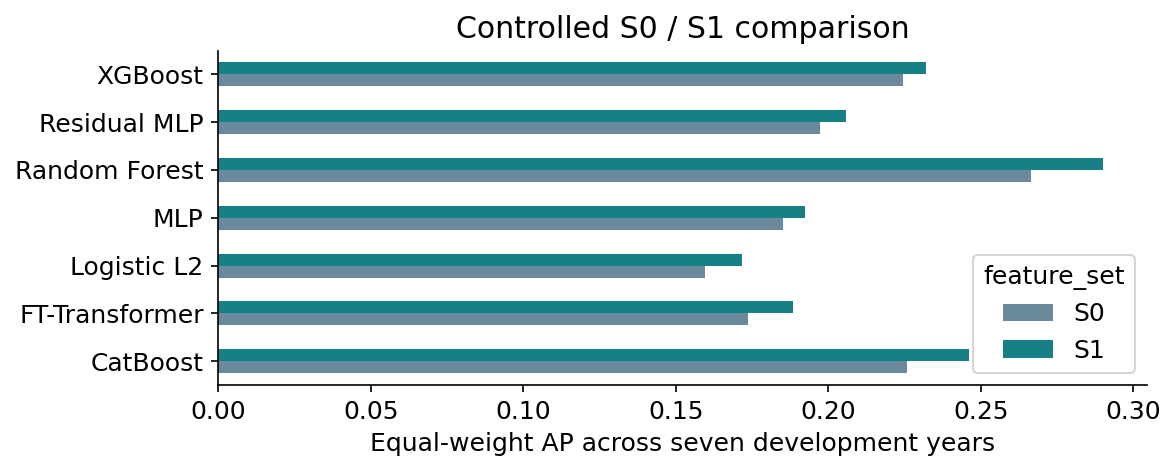

In [3]:
ablation = pd.read_csv(PUBLIC / "controlled_ablation_summary.csv")
display(ablation.pivot(index="recipe", columns="family", values="macro_year_AP"))
display(Image(filename=str(PUBLIC / "figures/development_features.png")))

## Selection and cost
Elastic Net and grouped permutation are nested inside each training window. No selection is a real candidate. Class weights derive from each current training role; ROS and SMOTE never alter scoring/calibration proportions.

In [4]:
stability = pd.read_csv(PUBLIC / "feature_selection_stability.csv")
display(stability.groupby(["family", "selector"]).agg(union_features=("feature", "size"), mean_jaccard=("mean_pairwise_Jaccard", "first")))
selection = json.loads((ROOT / "configs/final_selection.json").read_text())
print("Selected using development only:", selection["representatives"])

union_features  mean_jaccard
family       selector                                 
residual_mlp elastic_net              42      0.613095
             model_aware              60      1.000000
xgboost      elastic_net              42      0.613095
             model_aware              60      1.000000

Selected using development only: {'ML': 'random_forest__S1__95d8315d2d', 'DL': 'residual_mlp__S1__aaac4276aa'}


Inspect `selection.py`, `preprocessing.py` and `train.py`. Full training commands are in the README; running this notebook does not start an unbounded search or reopen historical selection.